In [55]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working in:", os.getcwd())

Working in: /Users/jamesfamodimu/Documents/energy-efficiency


In [42]:
from pathlib import Path
from itertools import combinations
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold, GroupKFold,
StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.mixture import GaussianMixture
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
roc_auc_score, brier_score_loss, accuracy_score, confusion_matrix)
import joblib
import json



SEED = 42


rng = np.random.default_rng(SEED)
pd.set_option("display.width", 110); pd.set_option("display.max_columns", 20)
for d in ["figures", "outputs", "model"]:
    Path(d).mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
"axes.spines.top": False, "axes.spines.right": False})
print("Setup is complete")

Setup is complete


In [43]:
from src.data import load_data, split_data, SEED, TARGETS, NUM, CAT, THRESH

df = load_data()
X_tr, X_te, Y_tr, Y_te = split_data(df)

def create_preprocessing_pipeline():
    numeric_transformer = StandardScaler()
    categorical_transformer = OneHotEncoder(drop = "first", handle_unknown = "ignore")
    
    return ColumnTransformer(
        transformers = [
            ("num", numeric_transformer, NUM),
            ("cat", categorical_transformer, CAT)
        ]
    )

print(X_tr.shape, X_te.shape)

(614, 7) (154, 7)


In [44]:
training_dataset = X_tr.join(Y_tr)
regression_terms = NUM + [f"C({category_column})" for category_column in CAT]

all_model_subsets = []
for combination_size in range(1, len(regression_terms) + 1):
    for term_subset in combinations(regression_terms, combination_size):
        formula_string = "heating_load ~ " + " + ".join(term_subset)
        fitted_model = smf.ols(formula_string, data = training_dataset).fit()
        all_model_subsets.append((fitted_model.bic, formula_string))

best_bic_score, best_formula_string = min(all_model_subsets)
best_ols_model = smf.ols(best_formula_string, data = training_dataset).fit()

print("Best by BIC:", best_formula_string)
print("adj R2 =", round(best_ols_model.rsquared_adj, 2))
print(best_ols_model.summary().tables[1])

Best by BIC: heating_load ~ compactness + roof_area + height + glazing_area + C(glazing_dist)
adj R2 = 0.92
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               41.4358      4.471      9.267      0.000      32.655      50.217
C(glazing_dist)[T.1]     4.7678      0.590      8.082      0.000       3.609       5.926
C(glazing_dist)[T.2]     4.9723      0.590      8.433      0.000       3.814       6.130
C(glazing_dist)[T.3]     4.5187      0.593      7.620      0.000       3.354       5.683
C(glazing_dist)[T.4]     4.8075      0.587      8.193      0.000       3.655       5.960
C(glazing_dist)[T.5]     4.4264      0.585      7.562      0.000       3.277       5.576
compactness            -44.1433      2.182    -20.234      0.000     -48.428     -39.859
roof_area               -0.1045      0.012     -8.500      0.000      -0.129      -0.080
he

Shapiro p = 5.409104886972655e-13
Breusch-Pagan p = 1.7427375818509693e-58


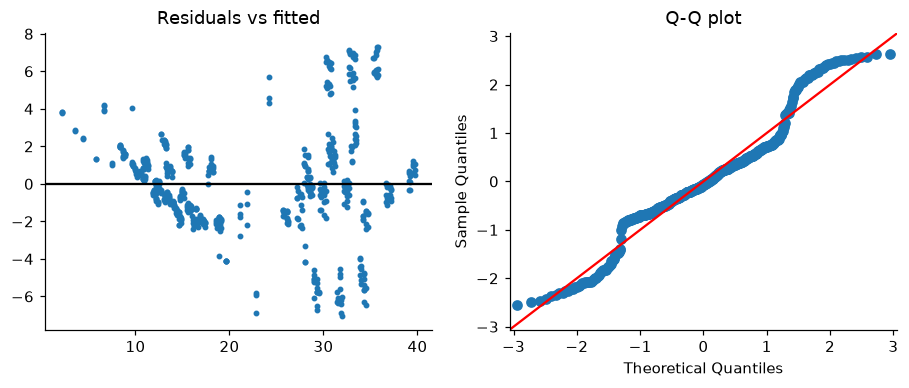

In [45]:
shapiro_test_p_value = stats.shapiro(best_ols_model.resid).pvalue
print("Shapiro p =", shapiro_test_p_value)

breusch_pagan_p_value = het_breuschpagan(best_ols_model.resid, best_ols_model.model.exog)[1]
print("Breusch-Pagan p =", breusch_pagan_p_value)

fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 3.5))

axes[0].scatter(best_ols_model.fittedvalues, best_ols_model.resid, s = 8)
axes[0].axhline(y = 0, color = "k")
axes[0].set_title("Residuals vs fitted")

sm.qqplot(best_ols_model.resid, line = "45", fit = True, ax = axes[1])
axes[1].set_title("Q-Q plot")

fig.savefig("figures/04_ols_diagnostics.png")
plt.show()


In [48]:
def create_interaction_preprocessing_pipeline():
    return Pipeline(
        steps = [
            ("base_preprocessing", create_preprocessing_pipeline()),
            ("interaction_features", PolynomialFeatures(degree = 2, include_bias = False))
        ]
    )

alpha_values = np.logspace(start = -4, stop = 3, num = 60)
model_candidates = {
    "OLS": Pipeline(
        steps = [
            ("preprocessing", create_preprocessing_pipeline()), 
            ("model", LinearRegression())
        ]
    ),
    "OLS + interactions": Pipeline(
        steps = [
            ("preprocessing", create_interaction_preprocessing_pipeline()), 
            ("model", LinearRegression())
        ]
    ),
    "Ridge": Pipeline(
        steps = [
            ("preprocessing", create_interaction_preprocessing_pipeline()), 
            ("model", RidgeCV(alphas=alpha_values))
        ]
    ),
    "Lasso": Pipeline(
        steps = [
            ("preprocessing", create_interaction_preprocessing_pipeline()), 
            ("model", LassoCV(alphas=alpha_values, max_iter=50_000))
        ]
    ),
    "Random Forest": Pipeline(
        steps = [
            ("preprocessing", create_preprocessing_pipeline()),
            ("model", RandomForestRegressor(n_estimators = 500, random_state = SEED, n_jobs = -1))
        ]
    ),
    "Gradient Boosting": Pipeline(
        steps = [
            ("preprocessing", create_preprocessing_pipeline()),
            ("model", GradientBoostingRegressor(random_state = SEED))
        ]
    ),
}

cross_validation_strategy = RepeatedKFold(n_splits = 10, n_repeats = 3, random_state = SEED)
cross_validation_records = []

for target_variable in TARGETS:
    for model_name, pipeline in model_candidates.items():
        validation_scores = cross_validate(
            estimator = pipeline, 
            X = X_tr, 
            y = Y_tr[target_variable], 
            cv = cross_validation_strategy, 
            n_jobs = -1,
            scoring=["neg_root_mean_squared_error", "r2"]
        )
        
        mean_rmse = -validation_scores["test_neg_root_mean_squared_error"].mean()
        mean_r2 = validation_scores["test_r2"].mean()
        
        cross_validation_records.append([target_variable, model_name, mean_rmse, mean_r2])

cv_results_table = pd.DataFrame(
    cross_validation_records, 
    columns = ["target", "model", "CV_RMSE", "CV_R2"]
)
cv_results_table.to_csv("outputs/cv_comparison.csv", index = False)

pivoted_rmse_summary = cv_results_table.pivot(
    index = "model", 
    columns = "target", 
    values = "CV_RMSE"
).round(2)

print(pivoted_rmse_summary)

target              cooling_load  heating_load
model                                         
Gradient Boosting           1.64          0.50
Lasso                       1.86          0.87
OLS                         3.22          2.81
OLS + interactions          1.57          0.47
Random Forest               1.92          0.56
Ridge                       1.83          0.82


In [49]:
hyperparameter_grid = {
    "m__n_estimators": [300, 600, 1000],
    "m__learning_rate": [0.03, 0.1],
    "m__max_depth": [2, 3, 4],
    "m__subsample": [0.8, 1.0]
}

final_models = {}
grid_search_records = {}

for target_variable in TARGETS:
    base_pipeline = Pipeline(
        steps=[
            ("preprocessing", create_preprocessing_pipeline()), 
            ("m", GradientBoostingRegressor(random_state=SEED))
        ]
    )
    
    cross_validation_fold = KFold(n_splits=10, shuffle=True, random_state=SEED)
    
    grid_search_optimizer = GridSearchCV(
        estimator=base_pipeline,
        param_grid=hyperparameter_grid, 
        cv=cross_validation_fold,
        scoring="neg_root_mean_squared_error", 
        n_jobs=-1
    ).fit(X_tr, Y_tr[target_variable])
    
    final_models[target_variable] = grid_search_optimizer.best_estimator_
    grid_search_records[target_variable] = grid_search_optimizer
    
    best_rmse_score = -grid_search_optimizer.best_score_
    print(target_variable, "CV RMSE", round(best_rmse_score, 2), grid_search_optimizer.best_params_)
 

heating_load CV RMSE 0.41 {'m__learning_rate': 0.1, 'm__max_depth': 4, 'm__n_estimators': 600, 'm__subsample': 1.0}
cooling_load CV RMSE 0.86 {'m__learning_rate': 0.1, 'm__max_depth': 4, 'm__n_estimators': 1000, 'm__subsample': 0.8}


In [33]:
leave_one_shape_out_records = []

selected_pipelines = [
    ("OLS", model_candidates["OLS"]),
    ("Random Forest", model_candidates["Random Forest"]),
    ("Tuned GB", final_models["heating_load"])
]

group_cross_validator = GroupKFold(n_splits=12)

for model_name, pipeline in selected_pipelines:
    validation_scores = cross_validate(
        estimator=pipeline,
        X=X_tr,
        y=Y_tr["heating_load"],
        cv=group_cross_validator,
        groups=X_tr["compactness"],
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    
    mean_rmse = -validation_scores["test_score"].mean()
    leave_one_shape_out_records.append([model_name, mean_rmse])

leave_one_shape_out_table = pd.DataFrame(
    leave_one_shape_out_records, 
    columns=["model", "heating_RMSE_unseen_shape"]
).round(2)

leave_one_shape_out_table.to_csv("outputs/loso_rmse.csv", index=False)
print(leave_one_shape_out_table)

           model  heating_RMSE_unseen_shape
0            OLS                       3.65
1  Random Forest                       4.38
2       Tuned GB                       5.25


In [51]:
test_metrics_records = []
test_predictions = {}

for target_variable in TARGETS:
    tuned_predictions = final_models[target_variable].predict(X_te)
    test_predictions[target_variable] = tuned_predictions
    
    tuned_rmse = np.sqrt(mean_squared_error(Y_te[target_variable], tuned_predictions))
    tuned_mae = mean_absolute_error(Y_te[target_variable], tuned_predictions)
    tuned_r2 = r2_score(Y_te[target_variable], tuned_predictions)
    
    test_metrics_records.append([
        target_variable, 
        tuned_rmse, 
        tuned_mae, 
        tuned_r2
    ])
    
    baseline_pipeline = model_candidates["OLS"].fit(X_tr, Y_tr[target_variable])
    baseline_predictions = baseline_pipeline.predict(X_te)
    
    baseline_rmse = np.sqrt(mean_squared_error(Y_te[target_variable], baseline_predictions))
    baseline_mae = mean_absolute_error(Y_te[target_variable], baseline_predictions)
    baseline_r2 = r2_score(Y_te[target_variable], baseline_predictions)
    
    test_metrics_records.append([
        f"{target_variable} (OLS baseline)", 
        baseline_rmse, 
        baseline_mae, 
        baseline_r2
    ])

test_metrics_table = pd.DataFrame(
    test_metrics_records, 
    columns=["target", "RMSE", "MAE", "R2"]
).round(2)

test_metrics_table.to_csv("outputs/test_metrics.csv", index=False)
print(test_metrics_table)

                        target  RMSE   MAE    R2
0                 heating_load  0.29  0.21  1.00
1  heating_load (OLS baseline)  2.87  2.11  0.92
2                 cooling_load  0.64  0.47  1.00
3  cooling_load (OLS baseline)  3.00  2.13  0.90


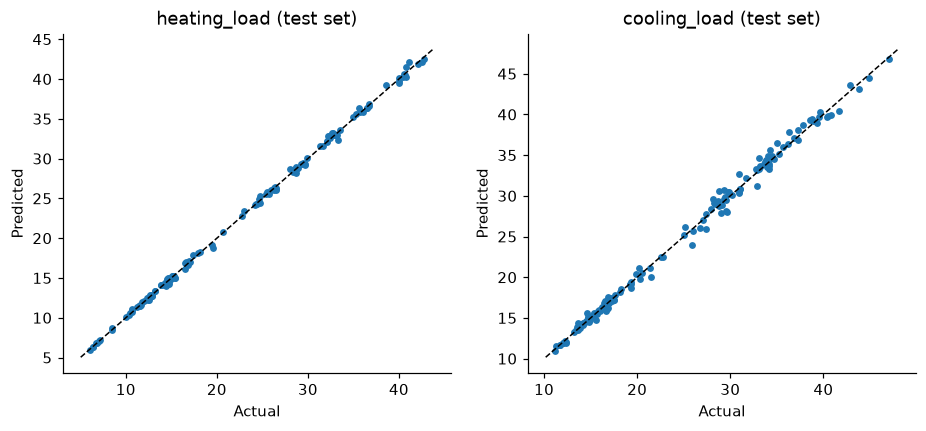

roof_area       6.64
glazing_area    4.16
compactness     3.34
height          2.76
wall_area       2.59
glazing_dist    0.28
orientation     0.16
dtype: float64


In [52]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
for ax, target_variable in zip(axes, TARGETS):
    ax.scatter(Y_te[target_variable], test_predictions[target_variable], s=12)
    
    axis_min = Y_te[target_variable].min() - 1
    axis_max = Y_te[target_variable].max() + 1
    ax.plot([axis_min, axis_max], [axis_min, axis_max], "k--", lw=1)
    
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.set_title(f"{target_variable} (test set)")

fig.savefig("figures/05_pred_vs_actual.png")
plt.show()

permutation_importance_results = permutation_importance(
    estimator=final_models["heating_load"], 
    X=X_te, 
    y=Y_te["heating_load"], 
    n_repeats=30,
    random_state=SEED, 
    scoring="neg_root_mean_squared_error"
)

feature_importances = pd.Series(
    permutation_importance_results.importances_mean, 
    index=X_te.columns
).sort_values(ascending=False).round(2)

feature_importances.to_csv("outputs/permutation_importance.csv")
print(feature_importances)

In [53]:
train_classification_target = (Y_tr["heating_load"] > THRESH).astype(int)
test_classification_target = (Y_te["heating_load"] > THRESH).astype(int)

logistic_regression_pipeline = Pipeline(
    steps=[
        ("preprocessing", create_preprocessing_pipeline()), 
        ("model", LogisticRegression(C=1.0, max_iter=5000))
    ]
).fit(X_tr, train_classification_target)

predicted_probabilities = logistic_regression_pipeline.predict_proba(X_te)[:, 1]
predicted_classes = predicted_probabilities >= 0.5

baseline_brier_score = test_classification_target.mean() * (1 - test_classification_target.mean())

print("ROC-AUC ", round(roc_auc_score(test_classification_target, predicted_probabilities), 2))
print("Brier   ", round(brier_score_loss(test_classification_target, predicted_probabilities), 2), "  (baseline:", round(baseline_brier_score, 2), ")")
print("Accuracy", round(accuracy_score(test_classification_target, predicted_classes), 2))
print(confusion_matrix(test_classification_target, predicted_classes))

ROC-AUC  0.97
Brier    0.06   (baseline: 0.19 )
Accuracy 0.95
[[110   4]
 [  4  36]]


In [56]:
joblib.dump(final_models, "model/tuned_models.joblib")
joblib.dump(logistic_regression_pipeline, "model/logit.joblib")
print("Saved:", sorted(p.name for p in Path("model").iterdir()))

Saved: ['.gitkeep', 'logit.joblib', 'tuned_models.joblib']
